# Tema : Introducción a los modelos de regresión y series de tiempo
![](src/img/logo_utb.png){width=40%}
![](src/img/logo_etd.png){width=40%}
- **Profesor:**
- **Fernando Salcedo Mejía, Eco Msc.**
- Programa de Ciencias de Datos | Escuela de transformación digital.
- 2026-1

## Ejemplo 1 : El consumo y el ingreso en Estados Unidos

- Queremos ver cómo se relacionan el cambio porcentual del consumo real (compra de bienes y servicios) y el cambio porcentual del ingreso personal real disponible en Estados Unidos.

$$
\Delta C_t = \beta_0 + \beta_1 \Delta Ingreso_t + \varepsilon_t
$$

- $\Delta C_t$ es el cambio porcentual en el gasto real de consumo personal.
- $\Delta Ingreso_t$ es el cambio porcentual en el ingreso personal real disponible.

- Usar el archivo `US_change.csv` para modelar.

## Librerías necesarias

In [ ]:
# Instalar todas las librerias necesarias previamente desde r-requirements.txt
suppressPackageStartupMessages({
  library(tidyverse)
  library(tsibble)     # Estructura de datos para series de tiempo
  library(fable)       # Modelos de series de tiempo
  library(feasts)      # Gráficos y características de series de tiempo
  library(ggtime)      # Visualización
})

# tamaño de los graficos
options(repr.plot.width = 8,
        repr.plot.height = 6,
        repr.plot.res = 300,
        repr.plot.pointsize = 14)

set_theme(theme_bw())

## Datos como serie de tiempo

- En R trabajamos las series de tiempo con un `tsibble`, que es una tabla donde una columna es el índice de tiempo. La función `yearquarter()` indica que los datos son trimestrales.

In [ ]:
us_change <- read_csv("../data/US_change.csv", show_col_types = FALSE) |>
  mutate(ds = yearquarter(ds)) |>
  select(Quarter = ds, Consumption = y, Income) |>
  as_tsibble(index = Quarter)

head(us_change)

Quarter,Consumption,Income
<qtr>,<dbl>,<dbl>
1970 Q1,0.6185664,1.0448013
1970 Q2,0.4519840,1.2256472
1970 Q3,0.8728718,1.5851538
1970 Q4,-0.2718479,-0.2395449
1971 Q1,1.9013450,1.9759249
1971 Q2,0.9148773,1.4459085


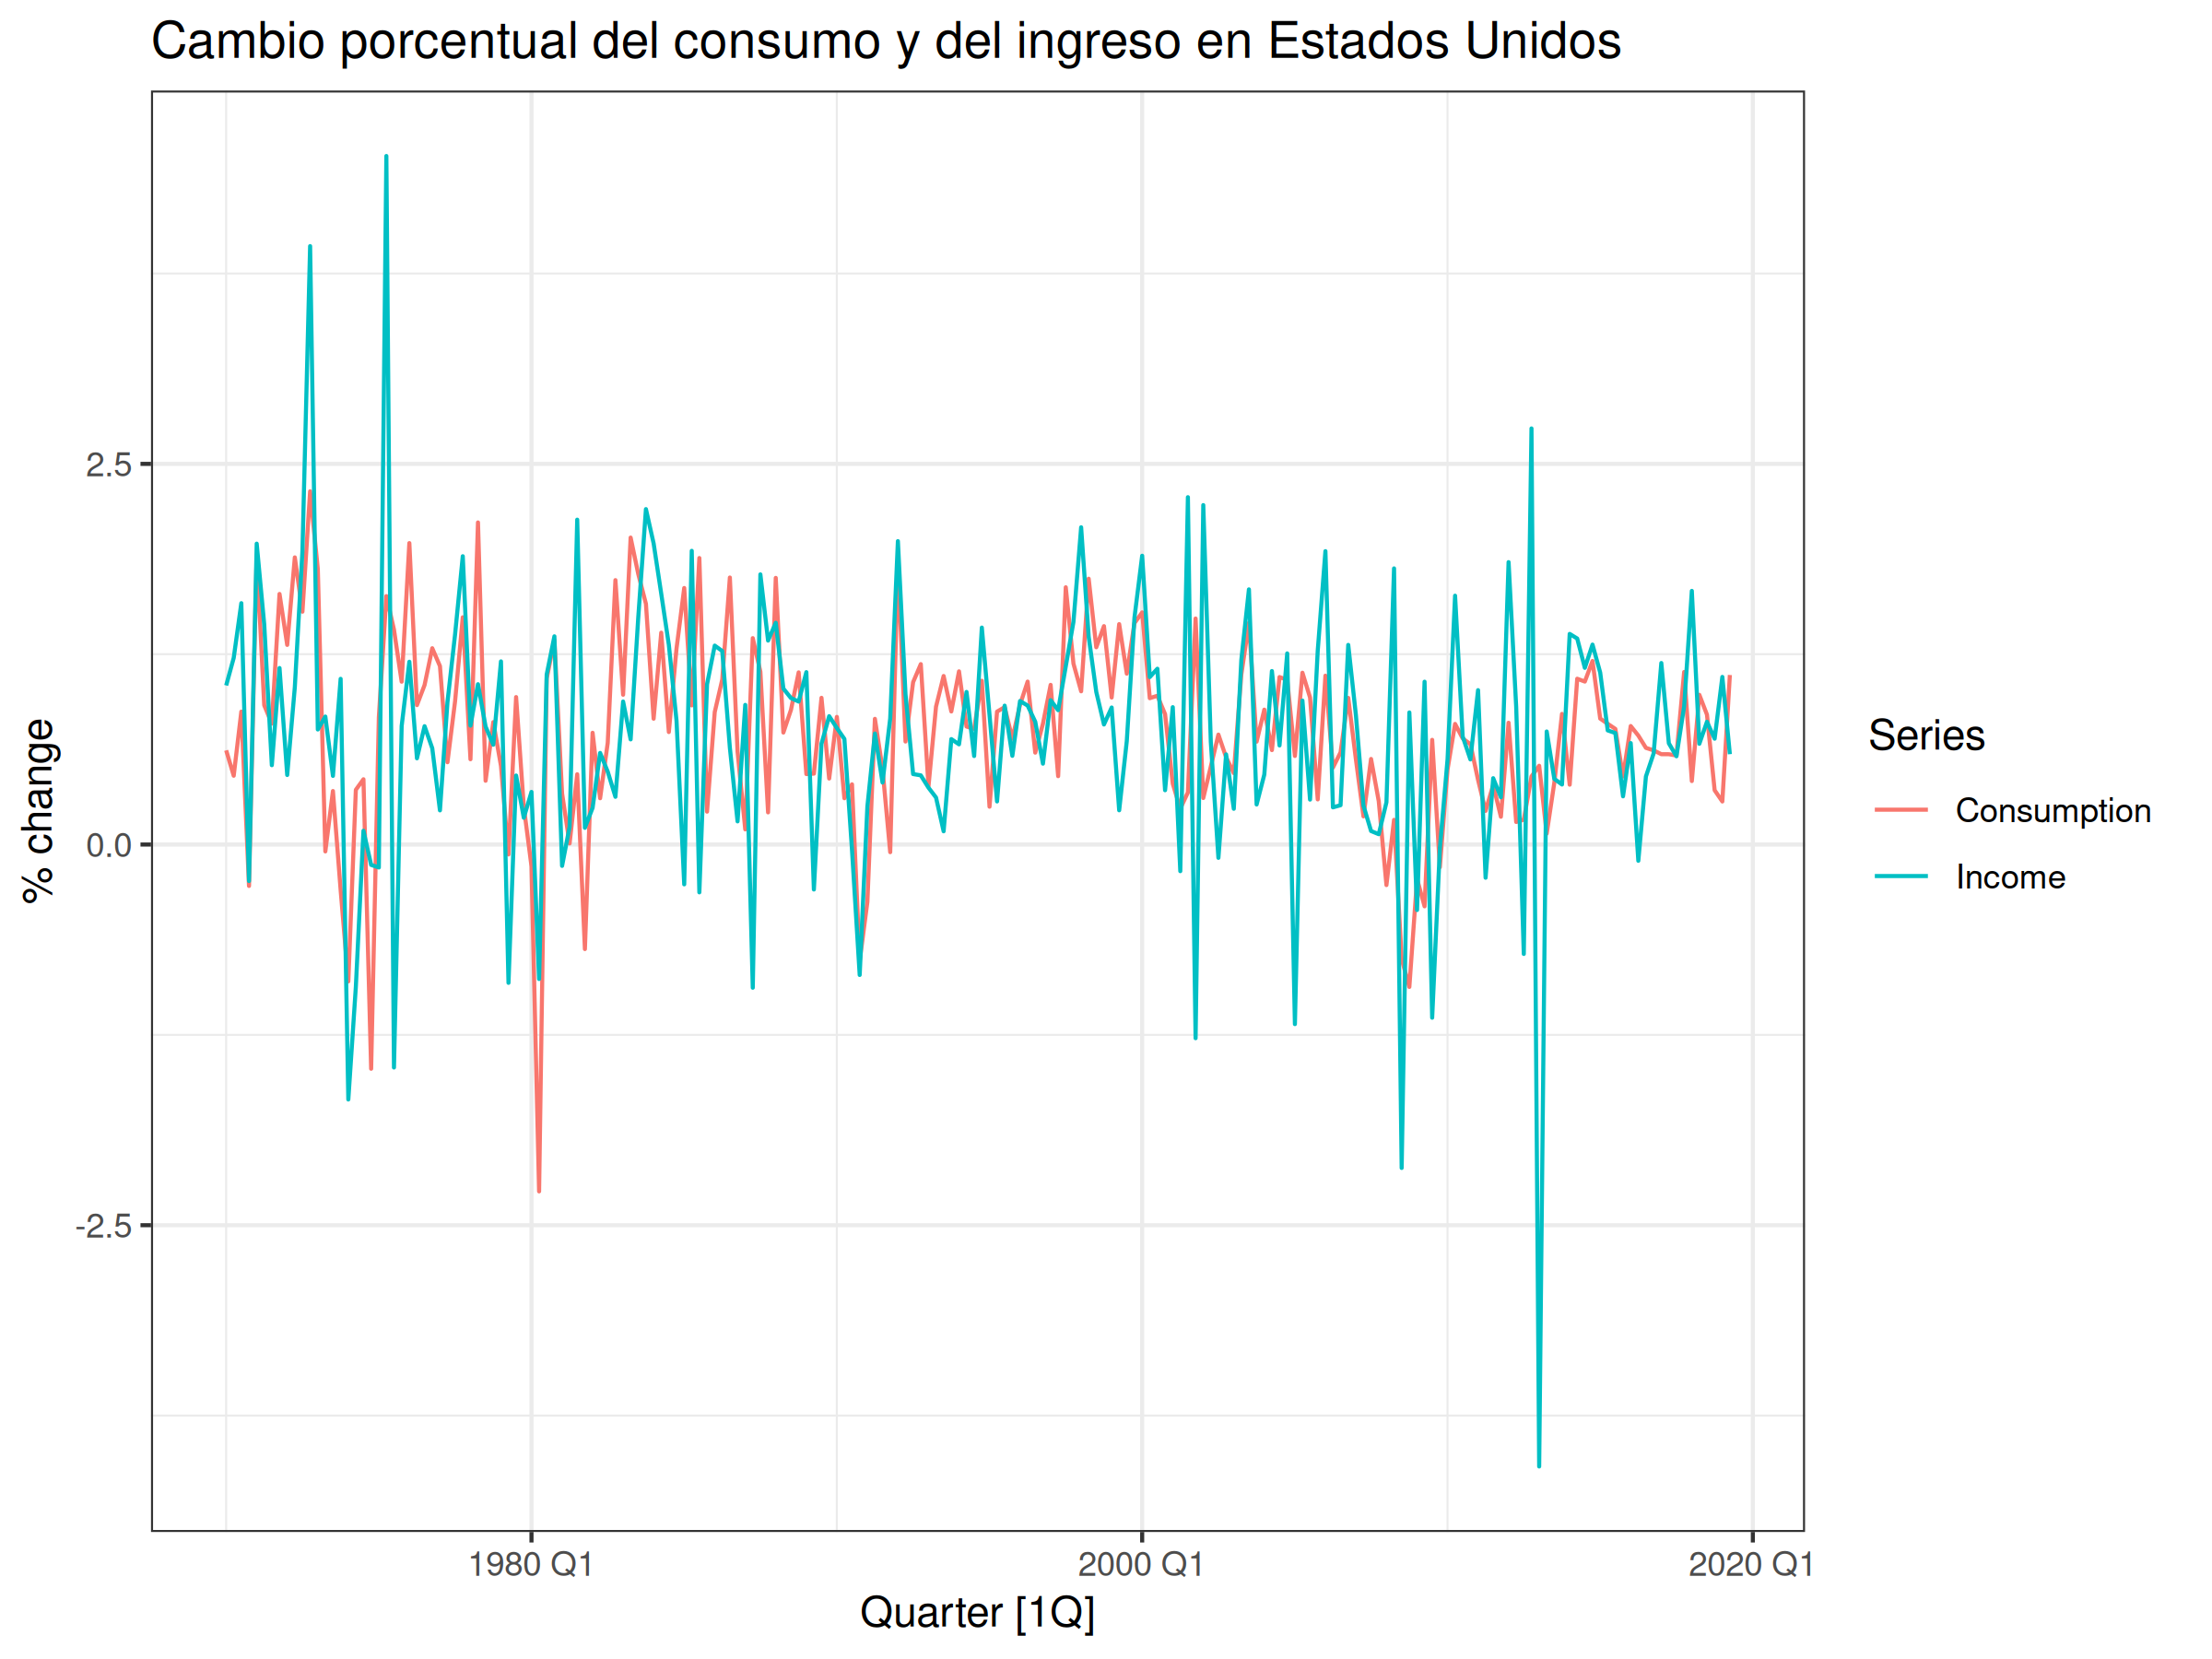

In [ ]:
# Gráfico de las dos series en el tiempo
us_change |>
  pivot_longer(c(Consumption, Income), names_to = "Series") |>
  autoplot(value) +
  labs(y = "% change", x = "Quarter [1Q]",
       title = "Cambio porcentual del consumo y del ingreso en Estados Unidos")

- Las dos series se mueven de forma parecida. Cuando el ingreso crece más, el consumo también tiende a crecer más, aunque el ingreso es más volátil que el consumo.

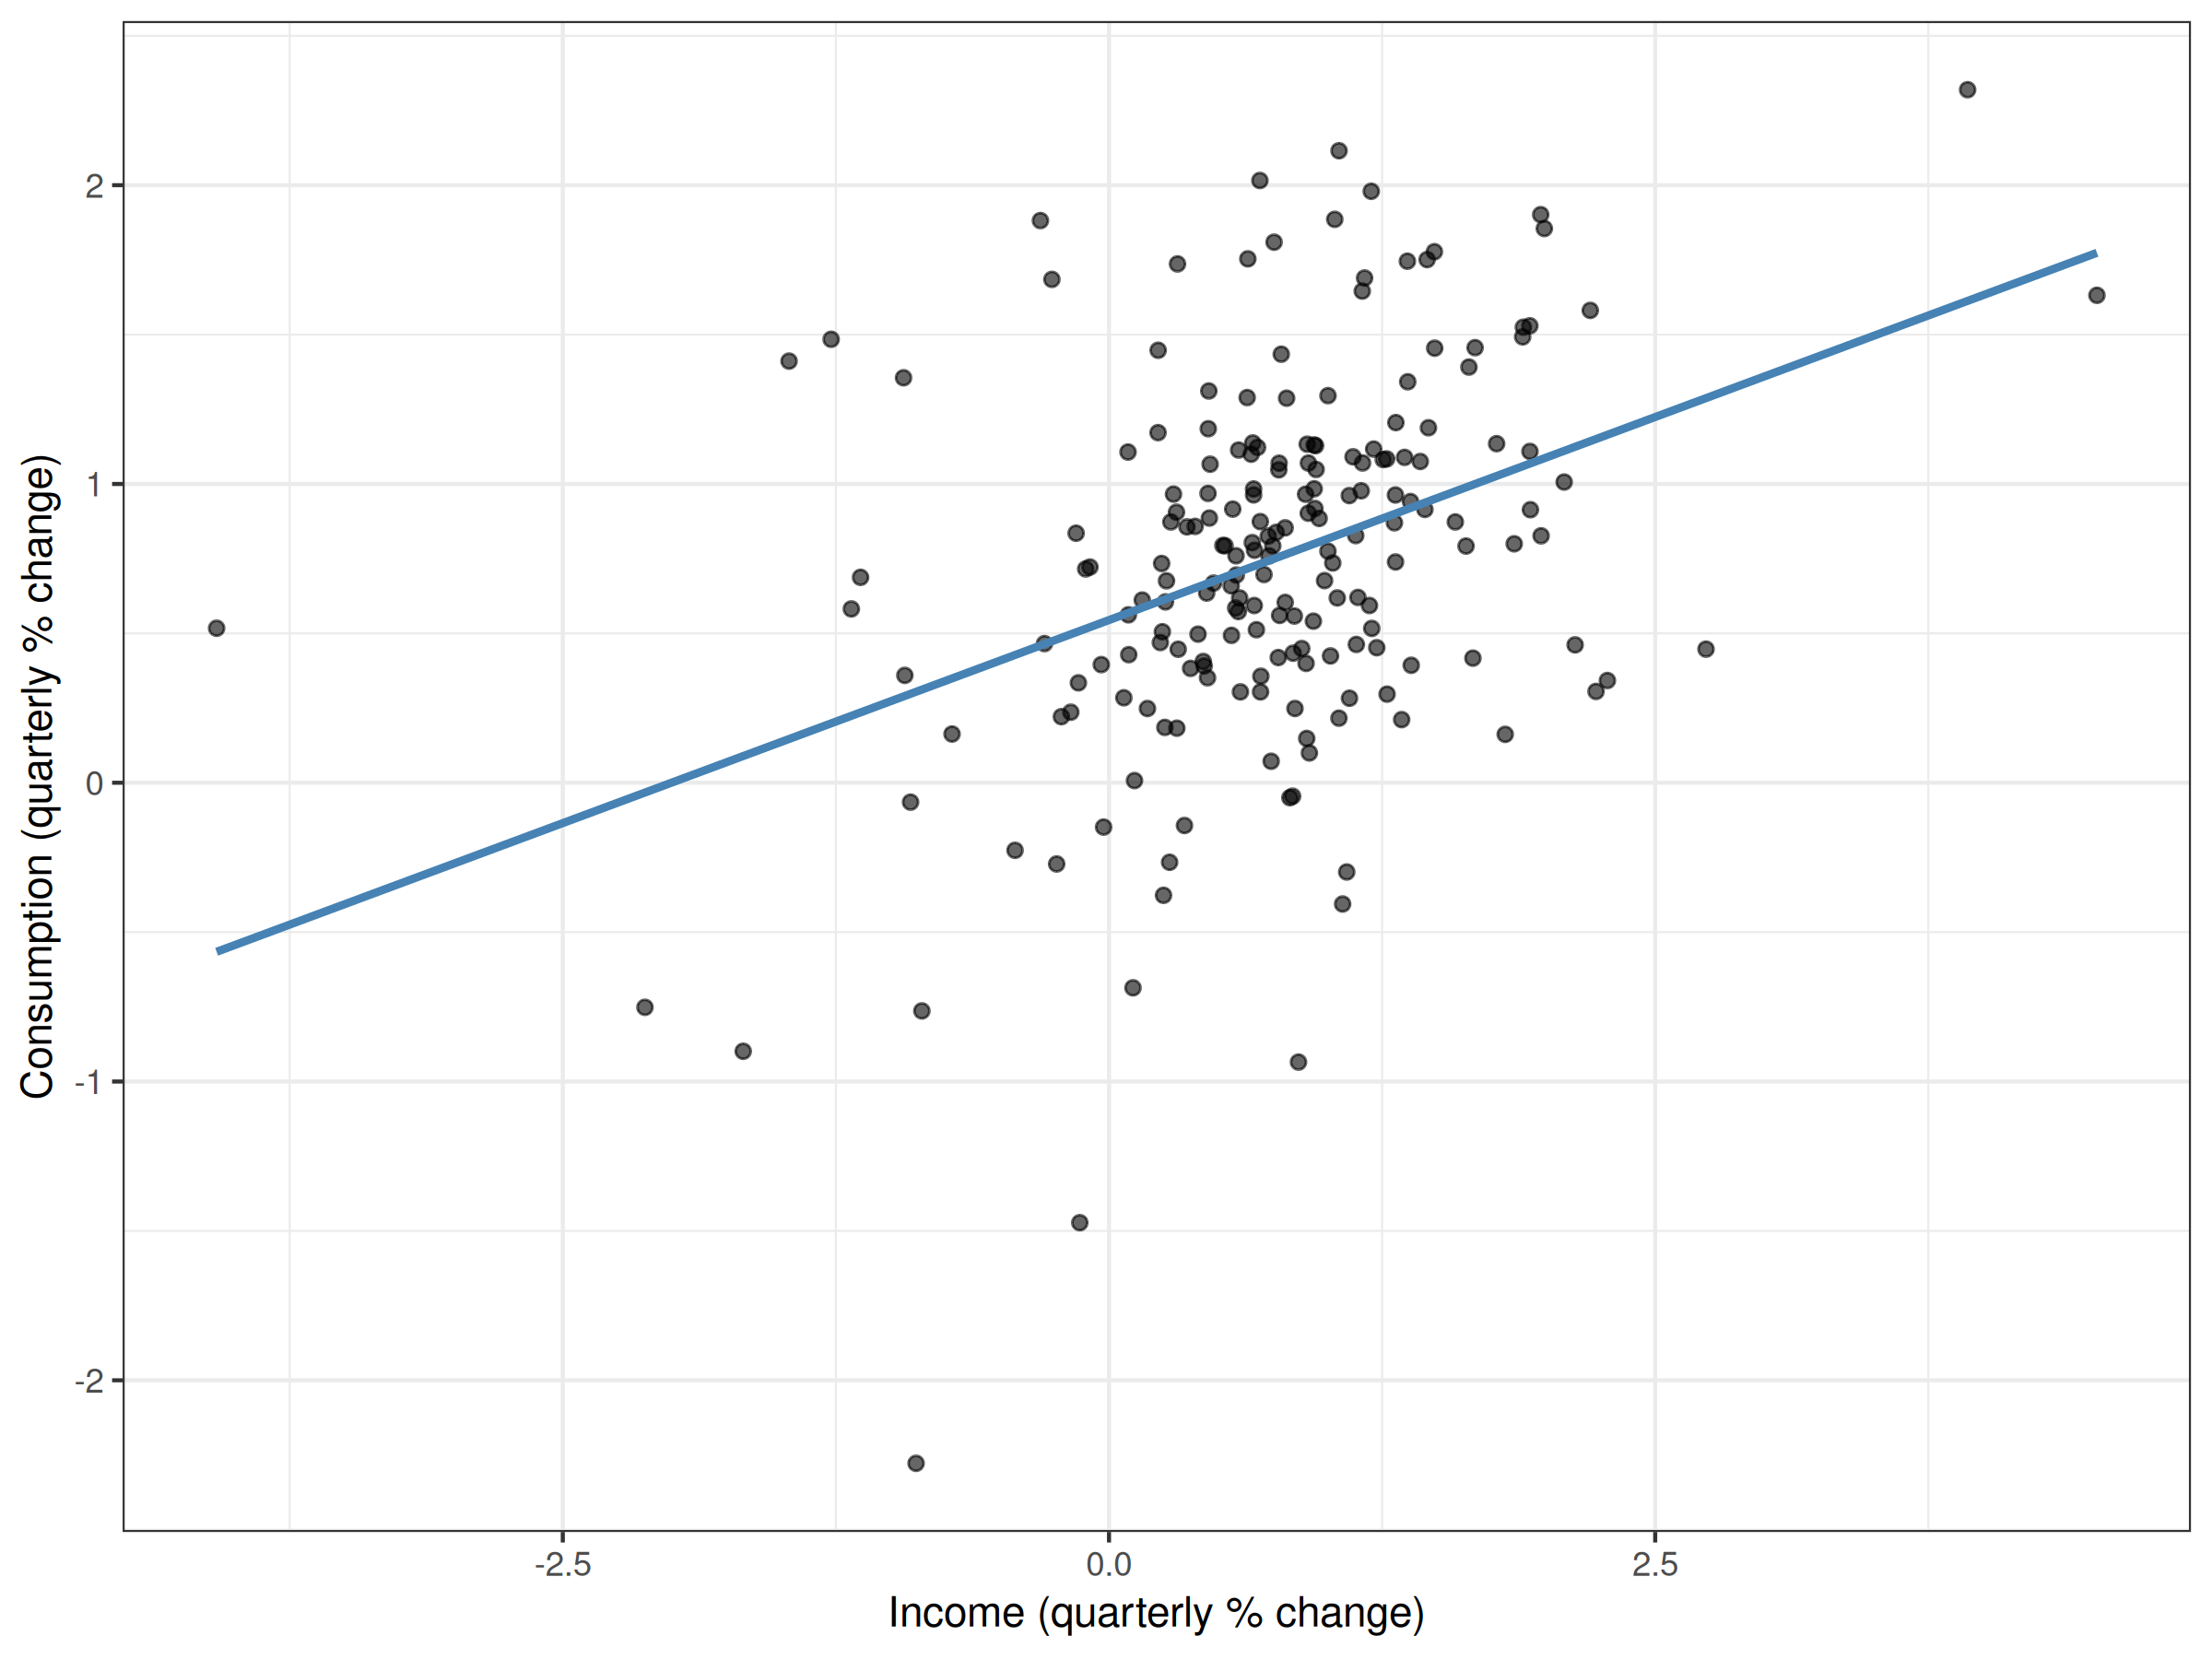

In [ ]:
# Diagrama de dispersión con la recta de regresión
us_change |>
  ggplot(aes(x = Income, y = Consumption)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE, colour = "steelblue") +
  labs(y = "Consumption (quarterly % change)", x = "Income (quarterly % change)")

In [ ]:
# Regresión lineal simple con TSLM
fit_consumo <- us_change |>
  model(TSLM(Consumption ~ Income))

report(fit_consumo)

Series: Consumption 
Model: TSLM 

Residuals:
     Min       1Q   Median       3Q      Max 
-2.58236 -0.27777  0.01862  0.32330  1.42229 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.54454    0.05403  10.079  < 2e-16 ***
Income       0.27183    0.04673   5.817  2.4e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.5905 on 196 degrees of freedom
Multiple R-squared: 0.1472,	Adjusted R-squared: 0.1429
F-statistic: 33.84 on 1 and 196 DF, p-value: 2.4022e-08


**Interpretación**

- La pendiente estimada indica que, en promedio, cuando el ingreso crece un punto porcentual más en un trimestre, el consumo crece 0.27 puntos porcentuales más. El intercepto indica que, cuando el ingreso no cambia, el consumo crece en promedio 0.54% por trimestre.
- El $R^2$ es 0.15, por lo que el ingreso solo explica el 15% de la variación del consumo. Otros factores, como la producción, el ahorro y el desempleo, también influyen.
- En los siguientes temas veremos cómo agregar más variables explicativas, cómo revisar los supuestos del modelo y cómo tratar la autocorrelación de los errores.